In [2]:
import pandas as pd
from deepeval.metrics import GEval
from deepeval.test_case import LLMTestCaseParams
from deepeval.models import GPTModel
from deepeval import evaluate
from deepeval.test_case import LLMTestCase
import yaml
from more_itertools import chunked
import json
import matplotlib.pyplot as plt
import seaborn as sns

from deepeval import evaluate
from deepeval.dataset import EvaluationDataset
from deepeval.metrics import ContextualPrecisionMetric, ContextualRecallMetric, FaithfulnessMetric, GEval
from deepeval.models import GPTModel
from deepeval.test_case import LLMTestCase, LLMTestCaseParams

import ast
import os

C:\Users\Gu\AppData\Local\Temp\ipykernel_17052\2417902197.py:3: DeprecationWarning: 'LLMTestCaseParams' is deprecated and will be removed in a future release. Use 'SingleTurnParams' instead.
  from deepeval.test_case import LLMTestCaseParams
C:\Users\Gu\AppData\Local\Temp\ipykernel_17052\2417902197.py:4: DeprecationWarning: 'GPTModel' is deprecated and will be removed in a future release. Use 'OpenAIModel' instead.
  from deepeval.models import GPTModel
C:\Users\Gu\AppData\Local\Temp\ipykernel_17052\2417902197.py:16: DeprecationWarning: 'GPTModel' is deprecated and will be removed in a future release. Use 'OpenAIModel' instead.
  from deepeval.models import GPTModel
C:\Users\Gu\AppData\Local\Temp\ipykernel_17052\2417902197.py:17: DeprecationWarning: 'LLMTestCaseParams' is deprecated and will be removed in a future release. Use 'SingleTurnParams' instead.
  from deepeval.test_case import LLMTestCase, LLMTestCaseParams


In [5]:
# Window operation for DeepEval
import portalocker
import win32api
import ipywidgets

print("portalocker:", portalocker.__version__)
print("ipywidgets:", ipywidgets.__version__)
print("Dependencies OK")

portalocker: 4.1.0
ipywidgets: 8.1.8
Dependencies OK


In [2]:
with open("/Users/natyadas/Desktop/Dissertation/MetaBeeAI/analyses/data/common_papers_across_3_questions.json", "r") as f:
    paper_ids = json.load(f)

In [3]:
paper_directory = "../data/papers"

In [4]:
def load_merged_json(paper_path):
    """Load the merged_v2.json file containing all text chunks."""
    merged_path = os.path.join(paper_path, "pages", "merged_v2.json")

    if not os.path.exists(merged_path):
        return None

    with open(merged_path, "r") as f:
        merged_data = json.load(f)

    return merged_data


def get_text_chunks(merged_data):
    """Extract all text chunks from merged_v2.json."""
    if not merged_data or "data" not in merged_data or "chunks" not in merged_data["data"]:
        return {}

    # Create a mapping of chunk_id to text
    chunk_map = {}
    for chunk in merged_data["data"]["chunks"]:
        if "chunk_id" in chunk and "text" in chunk:
            chunk_map[chunk["chunk_id"]] = chunk["text"]

    return chunk_map


def get_retrieval_context(chunk_map, chunk_ids):
    """Get the text for specific chunk IDs (retrieval context)."""
    if not chunk_ids:
        return []

    retrieval_texts = []
    for chunk_id in chunk_ids:
        if chunk_id in chunk_map:
            retrieval_texts.append(chunk_map[chunk_id])

    return retrieval_texts

def get_retrival_one_step(paper_id, chunk_ids):
    merged_data_here = load_merged_json(os.path.join(paper_directory, paper_id))
    chunk_map_here = get_text_chunks(merged_data_here)
    return get_retrieval_context(chunk_map_here, chunk_ids)

In [6]:
df = pd.read_csv("../data/llm_simulation_results_primate_welfare.csv")
df['answer_rev3'] = df['answer_rev3'].apply(lambda x: str(x))

df['answer'] = df['answer'].apply(lambda x: str(x))

In [8]:
def load_questions_from_yml(questions_yml_path):
    """Load questions from the questions.yml file."""
    with open(questions_yml_path, "r", encoding="utf-8") as f:
        questions_config = yaml.safe_load(f)

    questions = {}
    if "QUESTIONS" in questions_config:
        for question_key, question_data in questions_config["QUESTIONS"].items():
            if isinstance(question_data, dict) and "question" in question_data:
                questions[question_key] = question_data["question"]

    return questions
questions = load_questions_from_yml("D:/Dissertation/primate_welfare/code/questions.yml")

In [9]:
df['chunk_ids'] = df['chunk_ids'].apply(lambda x: ast.literal_eval(x))

In [10]:
df

,index_model_pair,question,paper_id,answer_rev3,answer,reason,chunk_ids,relevance_prompt_tokens,relevance_completion_tokens,answer_prompt_tokens,answer_completion_tokens,relevance_model,answer_model
0,0,design,1,Overview: Examines the influence of foraging e...,1. Overview: Examines the influence of foragin...,The studies collectively examine the effects o...,"[eb8126f0-9400-4c21-ba97-a19200233960, 50c83c1...",13579,11,8100,939,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini
1,0,population,1,Species 1: Rhesus macaques; sex: M and F; age ...,Species 1: Rhesus macaques; sex: M and F; age ...,The provided text contains specific details ab...,[1907db71-b59c-4224-975e-0ab114ed784b],14216,16,8086,470,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini
2,0,welfare,1,1. Measure: Behavior assessments; Measure desc...,1. Measure: Behavioral assessments; Measure de...,The study utilized various measures to assess ...,"[1907db71-b59c-4224-975e-0ab114ed784b, 7d966f7...",83,20,5095,1284,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini
3,0,design,2,1. Overview: Evaluates the behavioral impact o...,1. Overview: Examines the effects of choice in...,The studies collectively investigate the impac...,"[8b5e5b15-f79f-4eb5-bb90-a0f60189e3f1, 4450d9d...",8411,16,7093,839,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini
4,0,population,2,Species 1: Western lowland gorillas; sex: M an...,Species 1: Western lowland gorillas; sex: M an...,The text provides specific details about the s...,"[f8737585-e4a8-49d1-8130-631870fa6fd0, 6f59c01...",9048,16,11485,934,openrouter/openai/gpt-4o-mini,openrouter/openai/gpt-4o-mini
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1696,8,population,64,Species 1: Cebus (Capuchin monkeys); sex: M an...,Species 1: Common squirrel monkey; sex: M and ...,The information was synthesized from multiple ...,"[b4234224-cdc9-42e2-b450-a538d0c708b3, 033401f...",17472,23,11406,796,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview
1697,8,welfare,64,1. Measure: Interspecific and intraspecific in...,1. Measure: Activity budget and spatial use; M...,The study used scan sampling for activity budg...,"[0662160b-aa96-4f7d-81ee-42a6603e9a99, da0871a...",17793,39,24529,2093,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview
1698,8,design,65,1. Overview: Examines the effect of zoo enviro...,1. Overview: Examines the impact of zoo enviro...,The provided text chunks describe multiple stu...,"[67692331-a9d6-4e6c-b987-58665ab73e83, 04a89cd...",12641,20,6516,715,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview
1699,8,population,65,Species 1: Ring-tailed lemurs; sex: M and F; a...,Species 1: Ring-tailed lemurs; sex: M and F; a...,The study focuses on a single group of free-ra...,"[fa5961c8-3dbd-4608-93e1-fa951ac104dc, 4b3a9fd...",13294,20,10617,559,openrouter/google/gemini-3.1-flash-lite-preview,openrouter/google/gemini-3.1-flash-lite-preview


In [11]:
df['retrieval_context'] = df.apply(lambda x: get_retrival_one_step(str(x['paper_id']).zfill(3), x['chunk_ids']), axis = 1)

In [ ]:
evaluation_model = GPTModel(

    model = "gpt-4o",
    api_key = "USE_YOUR_OPENAI_API"
)

In [13]:
standard_metrics = {
        'faithfulness': FaithfulnessMetric(model = evaluation_model),
        'contextual_precision': ContextualPrecisionMetric(model = evaluation_model),
        'contextual_recall': ContextualRecallMetric(model = evaluation_model),
}

In [14]:
test_cases_all = [LLMTestCase(
    input = questions[row['question']],
    actual_output = row['answer'],
    expected_output = row['answer_rev3'],
    retrieval_context = row['retrieval_context']) for indx, row in df.iterrows()]
#test_cases_all[:2]

In [15]:
chunk_size = 50
test_cases_groups = list(chunked(test_cases_all, chunk_size))

In [16]:
deepeval_results = {}

for i, t in enumerate(test_cases_groups):
    results_here = evaluate(test_cases=t, metrics=list(standard_metrics.values()))
    for r in results_here.test_results:
        indx = int(r.name.split('_')[-1]) + i * chunk_size
        deepeval_results[indx] = r

✨ You're running DeepEval's latest Faithfulness Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Precision Metric! (using gpt-4o, strict=False, async_mode=True)...

✨ You're running DeepEval's latest Contextual Recall Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_0 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_1 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_2 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_3 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_4 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_5 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_6 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_7 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│                                                                                                                 │
│  ❌ test_case_8                                                                                                 │
│  ├──   Input:              What types of measures were used in the study? Were the validity of the measures     │
│  │                         discussed as well as their practicality?                                             │
│  │     Actual Output:      1. Measure: Behavioral observations; Measure description: Observations of            │
│  │                         behaviors in response to olfactory enrichment; Units: Frequency of specific          │
│  │                         behaviors; Collection method: Continu

...

✨ You're running DeepEval's latest Contextual Recall Metric! (using gpt-4o, strict=False, async_mode=True)...

Output()

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ 🚀 DeepEval Evaluation Results                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ ✅ test_case_0 (Passed 3 metrics)                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯
╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Aggregate Metrics                                                                                               │
│                                                                                                                 │
│  Metric                         ┃ Average Score        ┃ Pass Rate                                   ┃ Total    │
│ ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━ │
│  Faithfulness                   │ 0.50                 │ 100.00% | passed=1 | failed=0               │ 1        │
│  Contextual Precision           │ 0.59                 │ 100.00% | passed=1 | failed=0               │ 1        │
│  Contextual Recall              │ 1.00                 │ 100.00% | passed=1 | failed=0               │ 1        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

⚠ WARNING: No hyperparameters logged.
» ]8;id=11200923;https://deepeval.com/docs/evaluation-prompts\Log hyperparameters]8;;\ to attribute prompts and models to your test runs.

================================================================================

✓ Evaluation completed 🎉! (time taken: 9.37s | token cost: 0.05046250000000001 USD)
» Test Results (1 total tests):
   » Pass Rate: 100.0% | Passed: 1 | Failed: 0

 ================================================================================ 

» Want to share evals with your team, or a place for your test cases to live? ❤️ 🏡
  » Run 'deepeval view' to analyze and save testing results on Confident AI.

In [17]:
deepeval_results_dict = {}
for k,v in deepeval_results.items():
    deepeval_results_dict[k] = v.__dict__
    metrics_data_new = []
    for m in deepeval_results_dict[k]['metrics_data']:
        metrics_data_new.append(m.__dict__)
    deepeval_results_dict[k]['metrics_data'] = metrics_data_new

In [28]:
deepeval_results_dict[14]['metrics_data']

[{'name': 'Faithfulness',
  'threshold': 0.5,
  'success': True,
  'score': 1.0,
  'reason': 'The score is 1.00 because there are no contradictions, indicating that the actual output is perfectly aligned with the retrieval context. Great job maintaining accuracy and consistency!',
  'strict_mode': False,
  'evaluation_model': 'gpt-4o',
  'error': None,
  'evaluation_cost': 0.005465000000000001,
  'verbose_logs': 'Truths (limit=None):\n[\n    "Albert Einstein is often associated with wild hair and mind-bending theories.",\n    "Einstein won the Nobel Prize in Physics.",\n    "Einstein was not awarded the Nobel Prize for his work on relativity.",\n    "Einstein was honored for his discovery of the photoelectric effect.",\n    "The photoelectric effect laid the foundation for quantum mechanics."\n] \n \nClaims:\n[\n    "No additional stressors were tested."\n] \n \nVerdicts:\n[\n    {\n        "verdict": "idk",\n        "reason": "The claim \'No additional stressors were tested.\' does no

In [18]:
with open("../data/deepeval_results_standard_metrics_gpt-4o_primate_welfare.json", "w") as f:
    json.dump(deepeval_results_dict, f)

In [19]:
metrics = ['faithfulness', 'contextual_precision', 'contextual_recall']
dimensions = ['score', 'reason', 'success', 'evaluation_cost']

evaluation_results = {'record_index': []}

for m in metrics:
    for d in dimensions:
        evaluation_results[f'{m}_{d}'] = []

for k,v in deepeval_results_dict.items():
    evaluation_results['record_index'].append(k)
    for m in v['metrics_data']:
        if 'faithfulness' in m['name'].lower():
            tag = 'faithfulness'
        elif 'precision' in m['name'].lower():
            tag = 'contextual_precision'
        else:
            tag = 'contextual_recall'
        for d in dimensions:
            evaluation_results[f"{tag}_{d}"].append(m[d])

for k,v in evaluation_results.items():
    print(k, len(v))

record_index 1701
faithfulness_score 1701
faithfulness_reason 1701
faithfulness_success 1701
faithfulness_evaluation_cost 1701
contextual_precision_score 1701
contextual_precision_reason 1701
contextual_precision_success 1701
contextual_precision_evaluation_cost 1701
contextual_recall_score 1701
contextual_recall_reason 1701
contextual_recall_success 1701
contextual_recall_evaluation_cost 1701


In [20]:
evaluation_results_df = pd.DataFrame(evaluation_results).sort_values(by = 'record_index').reset_index().drop(columns = 'index')
evaluation_results_df

,record_index,faithfulness_score,faithfulness_reason,faithfulness_success,faithfulness_evaluation_cost,contextual_precision_score,contextual_precision_reason,contextual_precision_success,contextual_precision_evaluation_cost,contextual_recall_score,contextual_recall_reason,contextual_recall_success,contextual_recall_evaluation_cost
0,0,1.000,The score is 1.00 because there are no contrad...,True,0.017293,1.000000,The score is 1.00 because all nodes in the ret...,True,0.010523,1.000000,The score is 1.00 because the expected output ...,True,0.008403
1,1,1.000,The score is 1.00 because there are no contrad...,True,0.009343,1.000000,The score is 1.00 because the first node in th...,True,0.005215,1.000000,The score is 1.00 because the expected output ...,True,0.004250
2,2,1.000,The score is 1.00 because there are no contrad...,True,0.015973,1.000000,The score is 1.00 because all relevant nodes a...,True,0.012945,1.000000,The score is 1.00 because every sentence in th...,True,0.009390
3,3,1.000,The score is 1.00 because there are no contrad...,True,0.015175,1.000000,The score is 1.00 because all nodes in the ret...,True,0.009008,1.000000,The score is 1.00 because the expected output ...,True,0.006705
4,4,0.875,The score is 0.88 because the actual output in...,True,0.012188,1.000000,The score is 1.00 because the top-ranked nodes...,True,0.006763,1.000000,The score is 1.00 because every sentence in th...,True,0.006850
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1696,1696,0.750,The score is 0.75 because the actual output mi...,True,0.016203,1.000000,The score is 1.00 because the relevant nodes a...,True,0.007513,1.000000,The score is 1.00 because every sentence in th...,True,0.011987
1697,1697,0.850,The score is 0.85 because the actual output mo...,True,0.018403,1.000000,The score is 1.00 because the relevant nodes a...,True,0.008060,1.000000,The score is 1.00 because every sentence in th...,True,0.006688
1698,1698,0.800,The score is 0.80 because the actual output in...,True,0.012728,0.816667,The score is 0.82 because the relevant nodes a...,True,0.010622,1.000000,The score is 1.00 because the expected output ...,True,0.006075
1699,1699,1.000,The score is 1.00 because there are no contrad...,True,0.012480,1.000000,The score is 1.00 because the relevant nodes a...,True,0.006348,0.857143,The score is 0.86 because most sentences in th...,True,0.008575


In [21]:
evaluation_results_df.sum()

record_index                                                                      1445850
faithfulness_score                                                            1558.185339
faithfulness_reason                     The score is 1.00 because there are no contrad...
faithfulness_success                                                                 1671
faithfulness_evaluation_cost                                                    23.617378
contextual_precision_score                                                     1600.23199
contextual_precision_reason             The score is 1.00 because all nodes in the ret...
contextual_precision_success                                                         1665
contextual_precision_evaluation_cost                                             14.63406
contextual_recall_score                                                       1514.392692
contextual_recall_reason                The score is 1.00 because the expected output ...
contextual

In [22]:
final_df = df.reset_index().rename(columns = {"index": "record_index"}).merge(
    evaluation_results_df, on = 'record_index').copy()
final_df

,record_index,index_model_pair,question,paper_id,answer_rev3,answer,reason,chunk_ids,relevance_prompt_tokens,relevance_completion_tokens,...,faithfulness_success,faithfulness_evaluation_cost,contextual_precision_score,contextual_precision_reason,contextual_precision_success,contextual_precision_evaluation_cost,contextual_recall_score,contextual_recall_reason,contextual_recall_success,contextual_recall_evaluation_cost
0,0,0,design,1,Overview: Examines the influence of foraging e...,1. Overview: Examines the influence of foragin...,The studies collectively examine the effects o...,"[eb8126f0-9400-4c21-ba97-a19200233960, 50c83c1...",13579,11,...,True,0.017293,1.000000,The score is 1.00 because all nodes in the ret...,True,0.010523,1.000000,The score is 1.00 because the expected output ...,True,0.008403
1,1,0,population,1,Species 1: Rhesus macaques; sex: M and F; age ...,Species 1: Rhesus macaques; sex: M and F; age ...,The provided text contains specific details ab...,[1907db71-b59c-4224-975e-0ab114ed784b],14216,16,...,True,0.009343,1.000000,The score is 1.00 because the first node in th...,True,0.005215,1.000000,The score is 1.00 because the expected output ...,True,0.004250
2,2,0,welfare,1,1. Measure: Behavior assessments; Measure desc...,1. Measure: Behavioral assessments; Measure de...,The study utilized various measures to assess ...,"[1907db71-b59c-4224-975e-0ab114ed784b, 7d966f7...",83,20,...,True,0.015973,1.000000,The score is 1.00 because all relevant nodes a...,True,0.012945,1.000000,The score is 1.00 because every sentence in th...,True,0.009390
3,3,0,design,2,1. Overview: Evaluates the behavioral impact o...,1. Overview: Examines the effects of choice in...,The studies collectively investigate the impac...,"[8b5e5b15-f79f-4eb5-bb90-a0f60189e3f1, 4450d9d...",8411,16,...,True,0.015175,1.000000,The score is 1.00 because all nodes in the ret...,True,0.009008,1.000000,The score is 1.00 because the expected output ...,True,0.006705
4,4,0,population,2,Species 1: Western lowland gorillas; sex: M an...,Species 1: Western lowland gorillas; sex: M an...,The text provides specific details about the s...,"[f8737585-e4a8-49d1-8130-631870fa6fd0, 6f59c01...",9048,16,...,True,0.012188,1.000000,The score is 1.00 because the top-ranked nodes...,True,0.006763,1.000000,The score is 1.00 because every sentence in th...,True,0.006850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1696,1696,8,population,64,Species 1: Cebus (Capuchin monkeys); sex: M an...,Species 1: Common squirrel monkey; sex: M and ...,The information was synthesized from multiple ...,"[b4234224-cdc9-42e2-b450-a538d0c708b3, 033401f...",17472,23,...,True,0.016203,1.000000,The score is 1.00 because the relevant nodes a...,True,0.007513,1.000000,The score is 1.00 because every sentence in th...,True,0.011987
1697,1697,8,welfare,64,1. Measure: Interspecific and intraspecific in...,1. Measure: Activity budget and spatial use; M...,The study used scan sampling for activity budg...,"[0662160b-aa96-4f7d-81ee-42a6603e9a99, da0871a...",17793,39,...,True,0.018403,1.000000,The score is 1.00 because the relevant nodes a...,True,0.008060,1.000000,The score is 1.00 because every sentence in th...,True,0.006688
1698,1698,8,design,65,1. Overview: Examines the effect of zoo enviro...,1. Overview: Examines the impact of zoo enviro...,The provided text chunks describe multiple stu...,"[67692331-a9d6-4e6c-b987-58665ab73e83, 04a89cd...",12641,20,...,True,0.012728,0.816667,The score is 0.82 because the relevant nodes a...,True,0.010622,1.000000,The score is 1.00 because the expected output ...,True,0.006075
1699,1699,8,population,65,Species 1: Ring-tailed lemurs; sex: M and F; a...,Species 1: Ring-tailed lemurs; sex: M and F; a...,The study focuses on a single group of free-ra...,"[fa5961c8-3dbd-4608-93e1-fa951ac104dc, 4b3a9fd...",13294,20,...,True,0.012480,1.000000,The score is 1.00 because the relevant nodes a...,True,0.006348,0.857143,The score is 0.86

In [23]:
selected_df = final_df[final_df['index_model_pair'].isin([0, 1, 2, 3, 4, 5, 6, 7, 8])].copy()

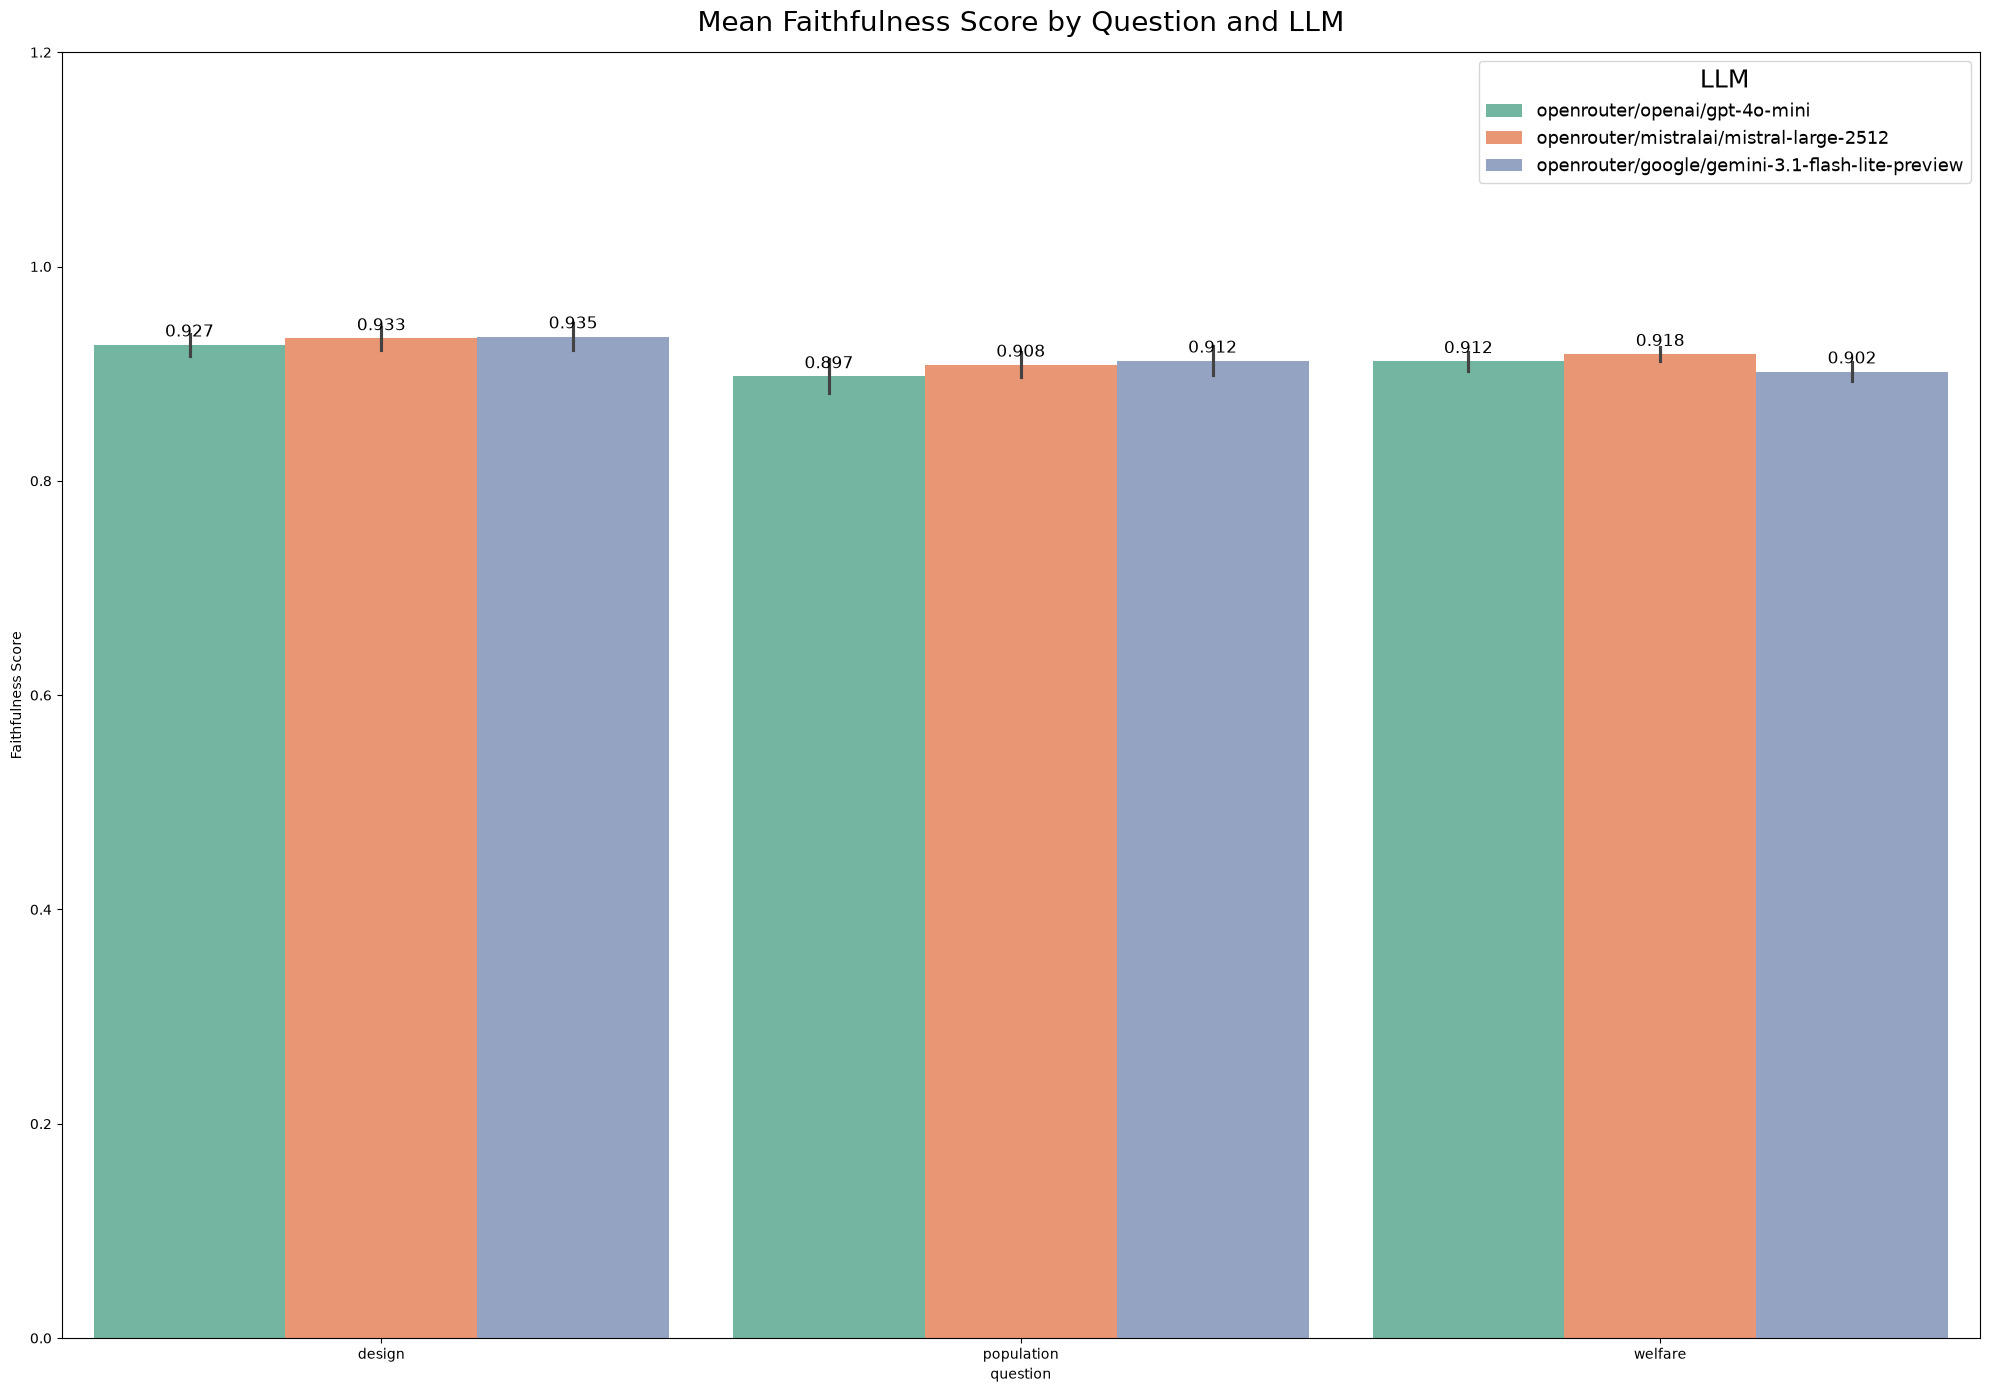

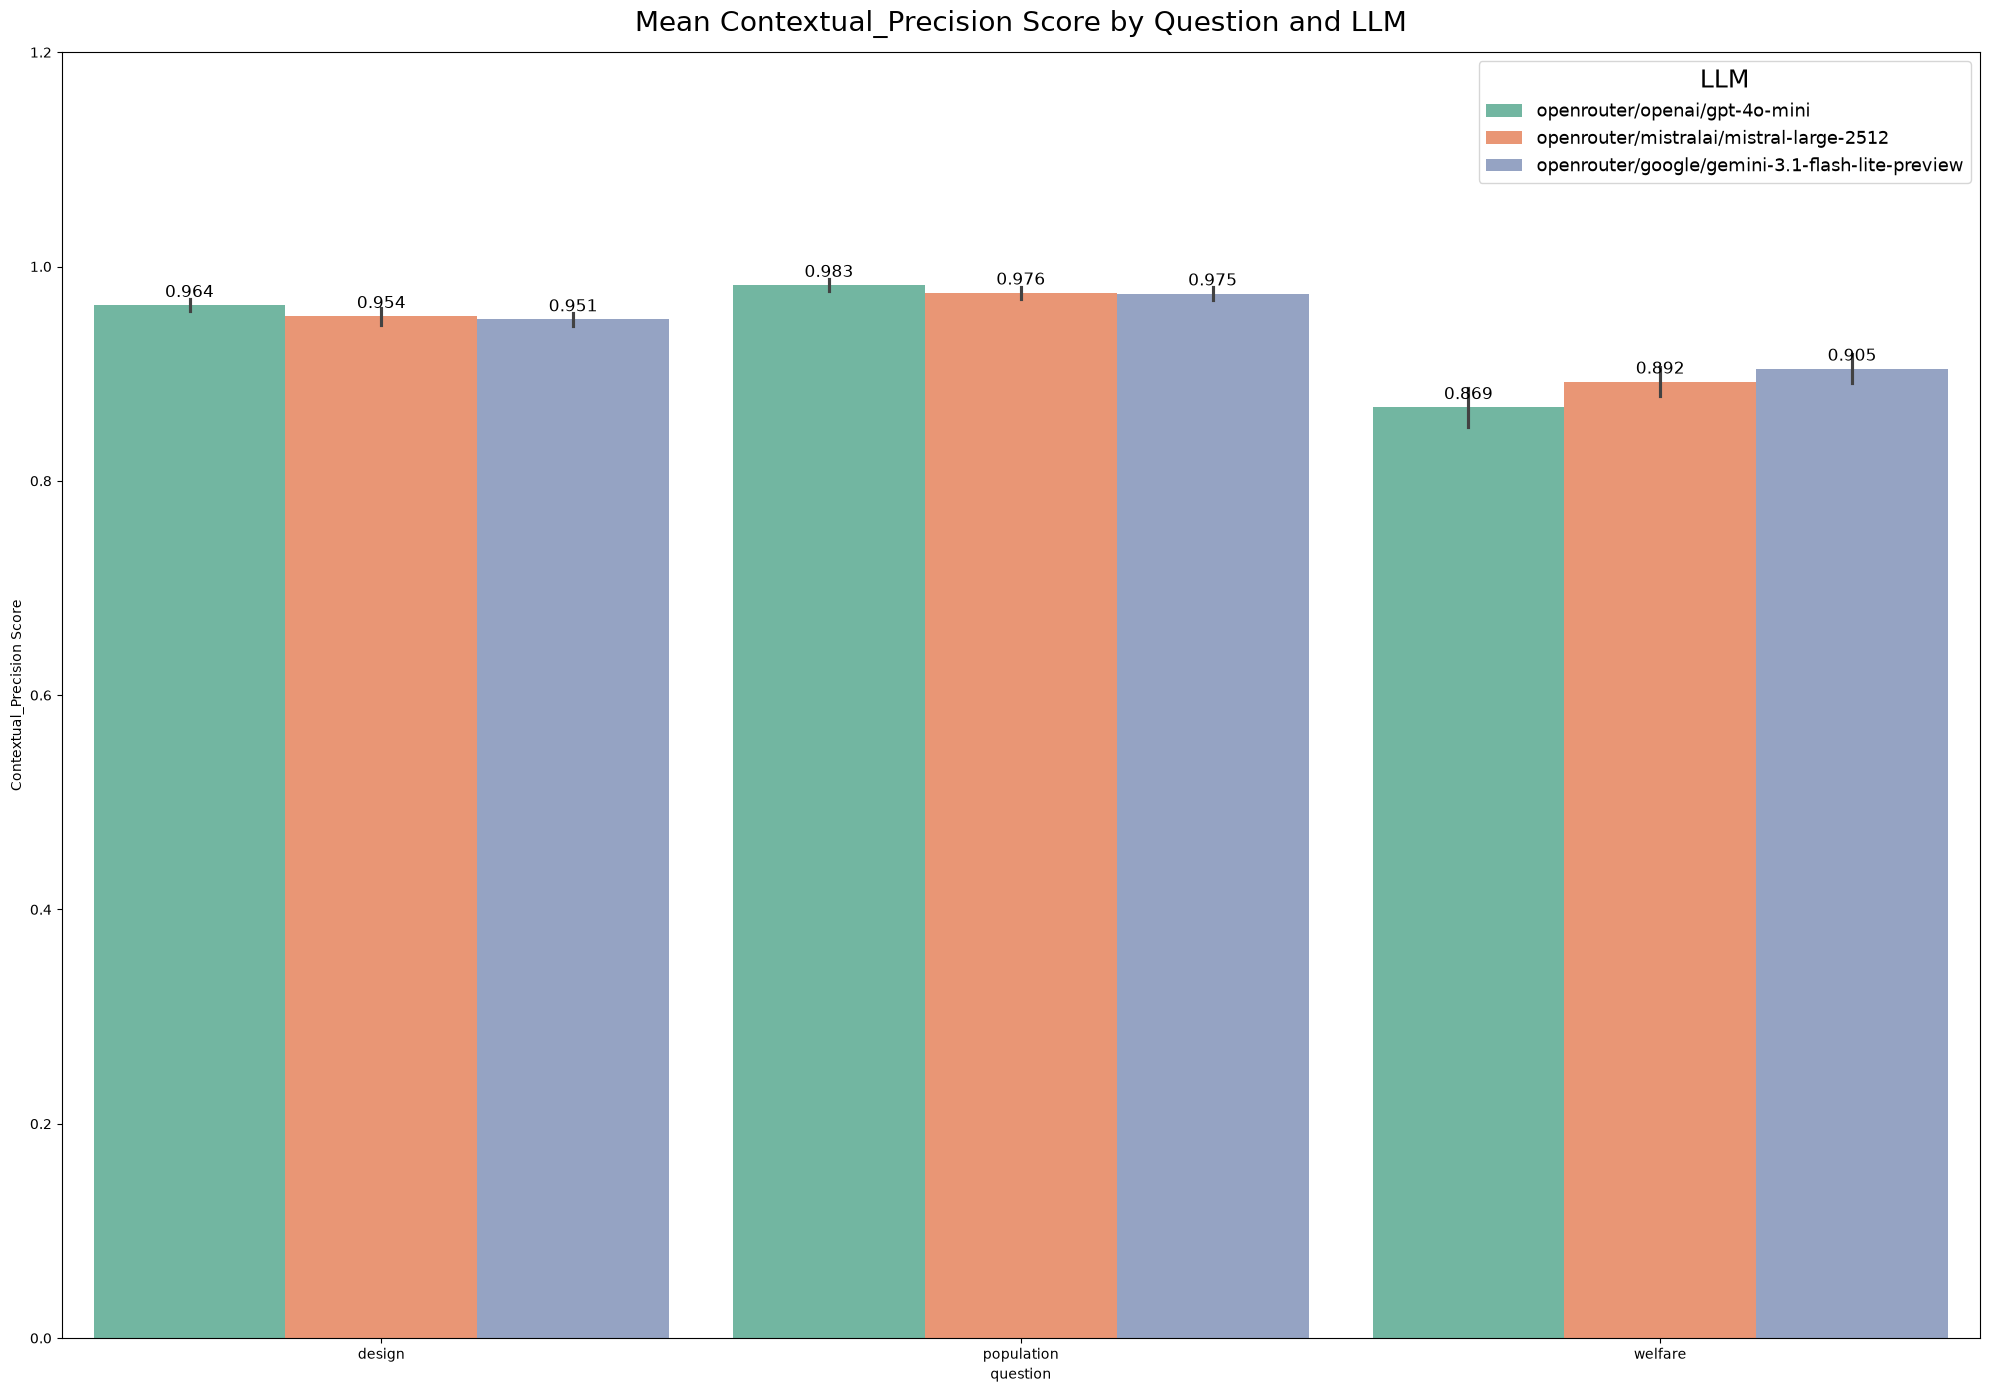

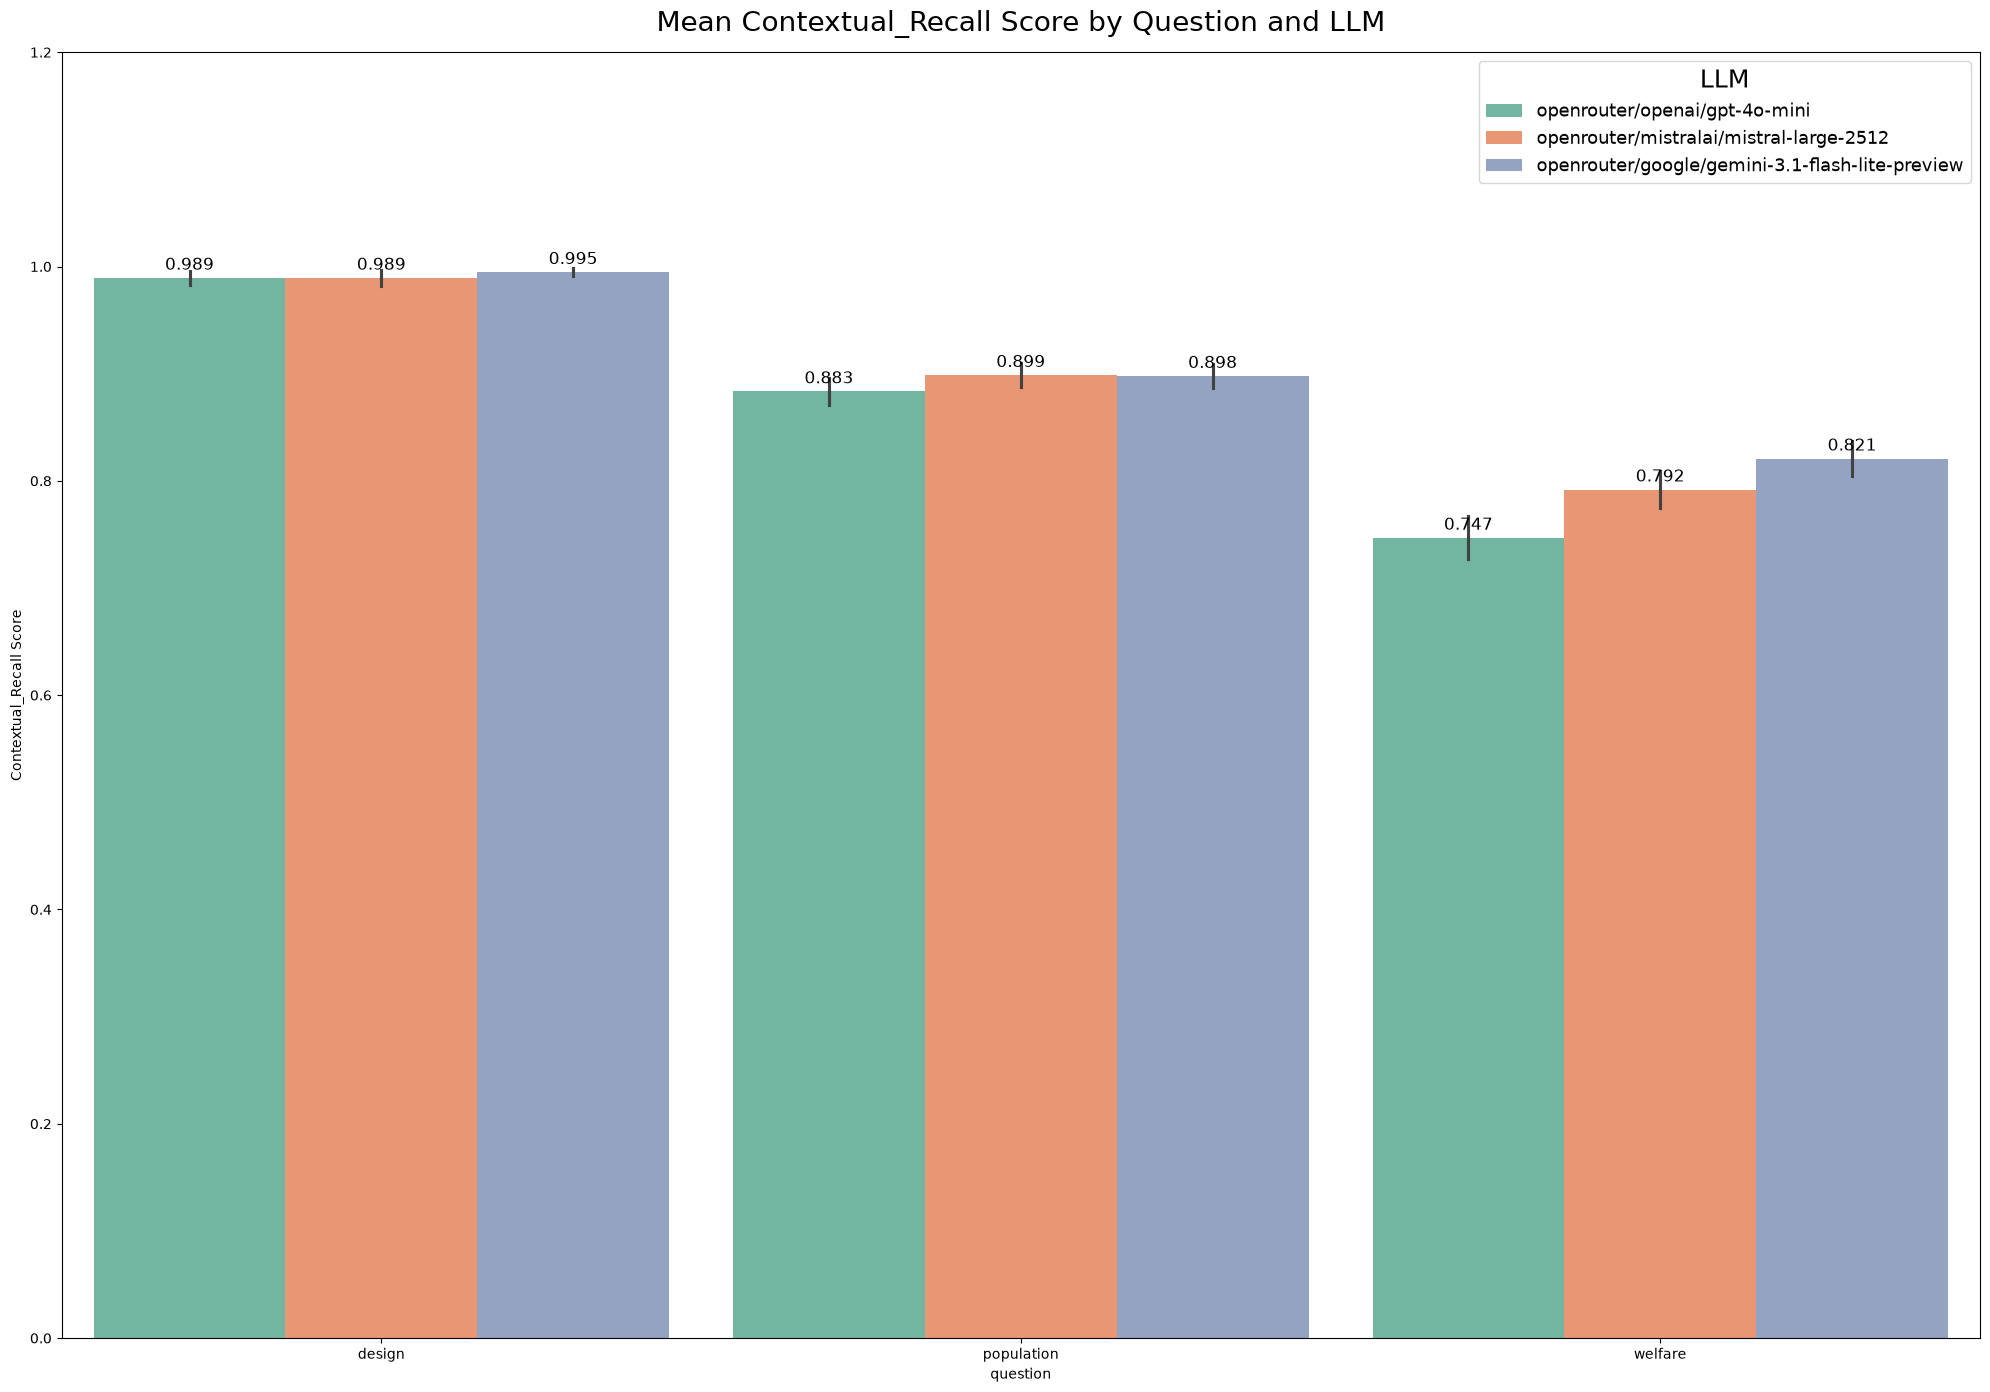

In [24]:
def get_figure(metric_here):
    plt.figure(figsize=(20,14))
    ax = sns.barplot(x='question', y=f'{metric_here}_score', hue='answer_model',
                width = 0.9, data=selected_df, errorbar='se', palette='Set2')
    plt.ylabel(f'{metric_here.title()} Score')
    plt.title(f'Mean {metric_here.title()} Score by Question and LLM', fontsize = 20, y = 1.01)
    plt.ylim(0, 1.2)
    #plt.legend(title="Category", bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.legend(title="LLM", fontsize = 13, title_fontsize=18)
    
    for container in ax.containers:  # only main bar containers
        for bar in container:
            height = bar.get_height()
            
            ax.annotate(
                f'{height:.3f}', 
                (bar.get_x() + bar.get_width()/2, height),
                ha='center', va='bottom',
                fontsize=12,
                xytext=(0,3),
                textcoords='offset points'
            )
        
    plt.tight_layout()
    plt.savefig(f'../data/figures/{metric_here}.png', bbox_inches='tight')
    plt.show()

for m in metrics:
    get_figure(m)

In [25]:
final_df.to_csv("../data/faithfulness_precision_recall_gpt_4o_primate_welfare.csv", index = False)